In [1]:

from google.colab import files
uploaded = files.upload()


Saving HospInfo.csv to HospInfo.csv


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

filename = next(iter(uploaded.keys()))
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())


Dataset loaded successfully!
Number of records: 4812
Number of columns: 29


,Provider ID,Hospital Name,Address,City,State,ZIP Code,County Name,Phone Number,Hospital Type,Hospital Ownership,...,Readmission national comparison footnote,Patient experience national comparison,Patient experience national comparison footnote,Effectiveness of care national comparison,Effectiveness of care national comparison footnote,Timeliness of care national comparison,Timeliness of care national comparison footnote,Efficient use of medical imaging national comparison,Efficient use of medical imaging national comparison footnote,Location
0,10005,MARSHALL MEDICAL CENTER SOUTH,2505 U S HIGHWAY 431 NORTH,BOAZ,AL,35957,MARSHALL,2565938310,Acute Care Hospitals,Government - Hospital District or Authority,...,NaN,Same as the national average,NaN,Same as the national average,NaN,Above the national average,NaN,Below the national average,NaN,"2505 U S HIGHWAY 431 NORTH\nBOAZ, AL\n"
1,10012,DEKALB REGIONAL MEDICAL CENTER,200 MED CENTER DRIVE,FORT PAYNE,AL,35968,DE KALB,2568453150,Acute Care Hospitals,Proprietary,...,NaN,Same as the national average,NaN,Same as the national average,NaN,Above the national average,NaN,Same as the national average,NaN,"200 MED CENTER DRIVE\nFORT PAYNE, AL\n"
2,10032,WEDOWEE HOSPITAL,209 NORTH MAIN STREET,WEDOWEE,AL,36278,RANDOLPH,2563572111,Acute Care Hospitals,Government - Hospital District or Authority,...,NaN,Not Available,Results are not available for this reporting p...,Same as the national average,NaN,Same as the national average,NaN,Not Available,Results are not available for this reporting p...,"209 NORTH MAIN STREET\nWEDOWEE, AL\n"
3,10095,HALE COUNTY HOSPITAL,508 GREEN STREET,GREENSBORO,AL,36744,HALE,3346243024,Acute Care Hospitals,Government - Local,...,Results are not available for this reporting p...,Not Available,Results are not available for this reporting p...,Below the national average,NaN,Same as the national average,NaN,Not Available,Results are not available for this reporting p...,"508 GREEN STREET\nGREENSBORO, AL\n"
4,10131,CRESTWOOD MEDICAL CENTER,ONE HOSPITAL DR SE,HUNTSVILLE,AL,35801,MADISON,2568823100,Acute Care Hospitals,Proprietary,...,NaN,Same as the national average,NaN,Same as the national average,NaN,Same as the national average,NaN,Same as the national average,NaN,"ONE HOSPITAL DR SE\nHUNTSVILLE, AL\n"


In [3]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.dummy import DummyClassifier


In [4]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Column names:
['Provider ID', 'Hospital Name', 'Address', 'City', 'State', 'ZIP Code', 'County Name', 'Phone Number', 'Hospital Type', 'Hospital Ownership', 'Emergency Services', 'Meets criteria for meaningful use of EHRs', 'Hospital overall rating', 'Hospital overall rating footnote', 'Mortality national comparison', 'Mortality national comparison footnote', 'Safety of care national comparison', 'Safety of care national comparison footnote', 'Readmission national comparison', 'Readmission national comparison footnote', 'Patient experience national comparison', 'Patient experience national comparison footnote', 'Effectiveness of care national comparison', 'Effectiveness of care national comparison footnote', 'Timeliness of care national comparison', 'Timeliness of care national comparison footnote', 'Efficient use of medical imaging national comparison', 'Efficient use of medical imaging national comparison footnote', 'Location']

Dataset information:
<class 'pandas.core.frame.DataFram

In [5]:

missing_values = df.isnull().sum()

missing_table = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df) * 100).round(2)
}).sort_values("Missing Percentage", ascending=False)

display(missing_table)


,Missing Values,Missing Percentage
Readmission national comparison footnote,3795,78.87
Effectiveness of care national comparison footnote,3610,75.02
Timeliness of care national comparison footnote,3546,73.69
Mortality national comparison footnote,3460,71.90
Patient experience national comparison footnote,3443,71.55
Hospital overall rating footnote,3414,70.95
Efficient use of medical imaging national comparison footnote,2779,57.75
Safety of care national comparison footnote,2644,54.95
Meets criteria for meaningful use of EHRs,144,2.99
County Name,15,0.31


In [6]:

print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Dataset shape after removing duplicates:", df.shape)


Duplicate rows: 0
Dataset shape after removing duplicates: (4812, 29)


In [7]:

display(df.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Provider ID,4812.0,NaN,NaN,NaN,268294.422901,157109.340215,10001.0,140185.75,260043.5,390222.25,670118.0
Hospital Name,4812,4623,MEMORIAL HOSPITAL,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Address,4812,4784,100 HOSPITAL DRIVE,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,4812,2947,CHICAGO,29,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,4812,56,TX,411,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ZIP Code,4812.0,NaN,NaN,NaN,53990.132377,26915.91687,603.0,33015.25,55410.5,76035.5,99929.0
County Name,4797,1563,LOS ANGELES,83,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Phone Number,4812.0,NaN,NaN,NaN,5848243618.000208,2332196478.128277,936933841.0,4014562756.25,6053360047.0,7877574350.0,9898943000.0
Hospital Type,4812,3,Acute Care Hospitals,3369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Hospital Ownership,4812,10,Voluntary non-profit - Private,2052,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:

target = "Hospital overall rating"

df[target] = df[target].astype("string").str.strip()

valid_rating = df[target].isin(["1", "2", "3", "4", "5"])
df = df.loc[valid_rating].copy()

df[target] = df[target].astype(int)

print("Records with valid ratings:", len(df))
print("\nRating distribution:")
print(df[target].value_counts().sort_index())


Records with valid ratings: 3567

Rating distribution:
Hospital overall rating
1     107
2     678
3    1761
4     939
5      82
Name: count, dtype: int64


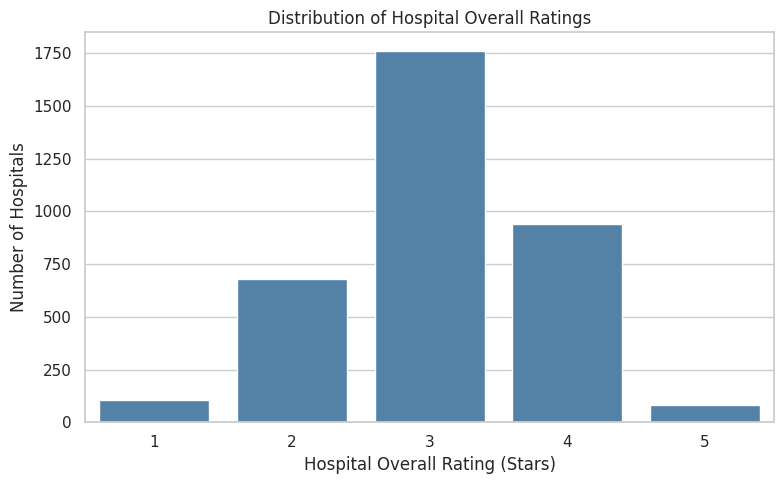

In [9]:

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x=target, color="steelblue")

plt.title("Distribution of Hospital Overall Ratings")
plt.xlabel("Hospital Overall Rating (Stars)")
plt.ylabel("Number of Hospitals")
plt.tight_layout()
plt.show()


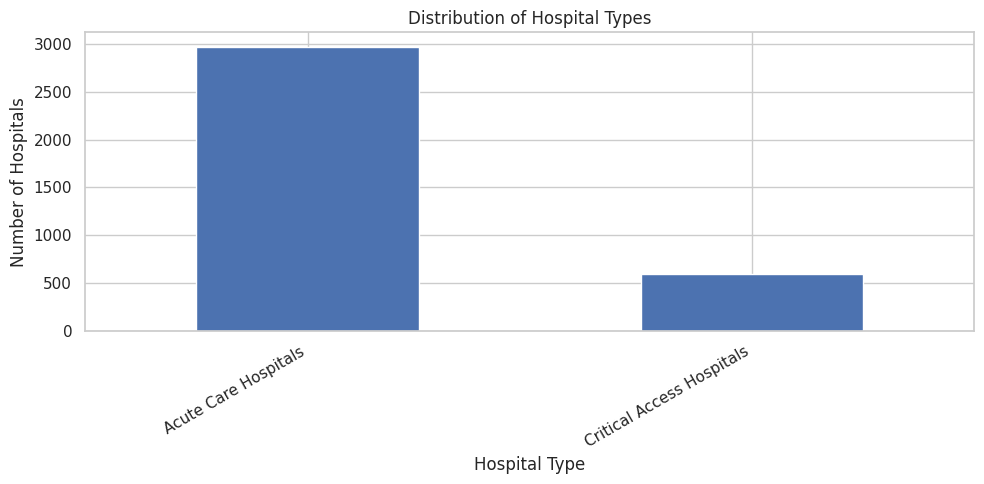

In [10]:

plt.figure(figsize=(10, 5))

df["Hospital Type"].value_counts().plot(kind="bar")

plt.title("Distribution of Hospital Types")
plt.xlabel("Hospital Type")
plt.ylabel("Number of Hospitals")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


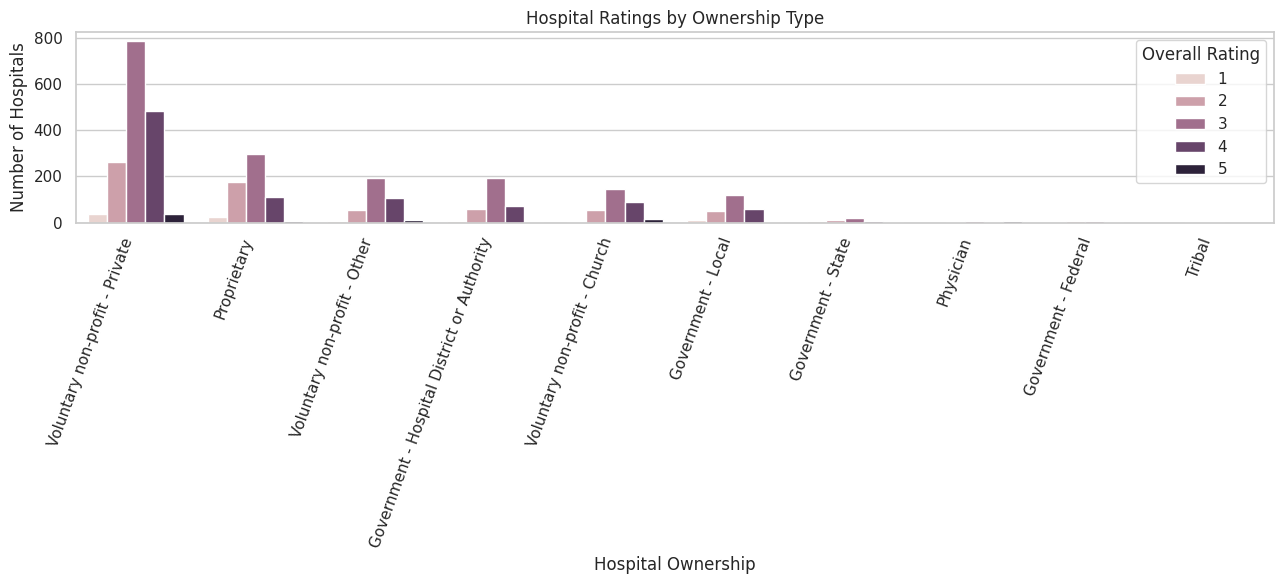

In [11]:

plt.figure(figsize=(13, 6))

sns.countplot(
    data=df,
    x="Hospital Ownership",
    hue=target,
    order=df["Hospital Ownership"].value_counts().index
)

plt.title("Hospital Ratings by Ownership Type")
plt.xlabel("Hospital Ownership")
plt.ylabel("Number of Hospitals")
plt.xticks(rotation=70, ha="right")
plt.legend(title="Overall Rating")
plt.tight_layout()
plt.show()


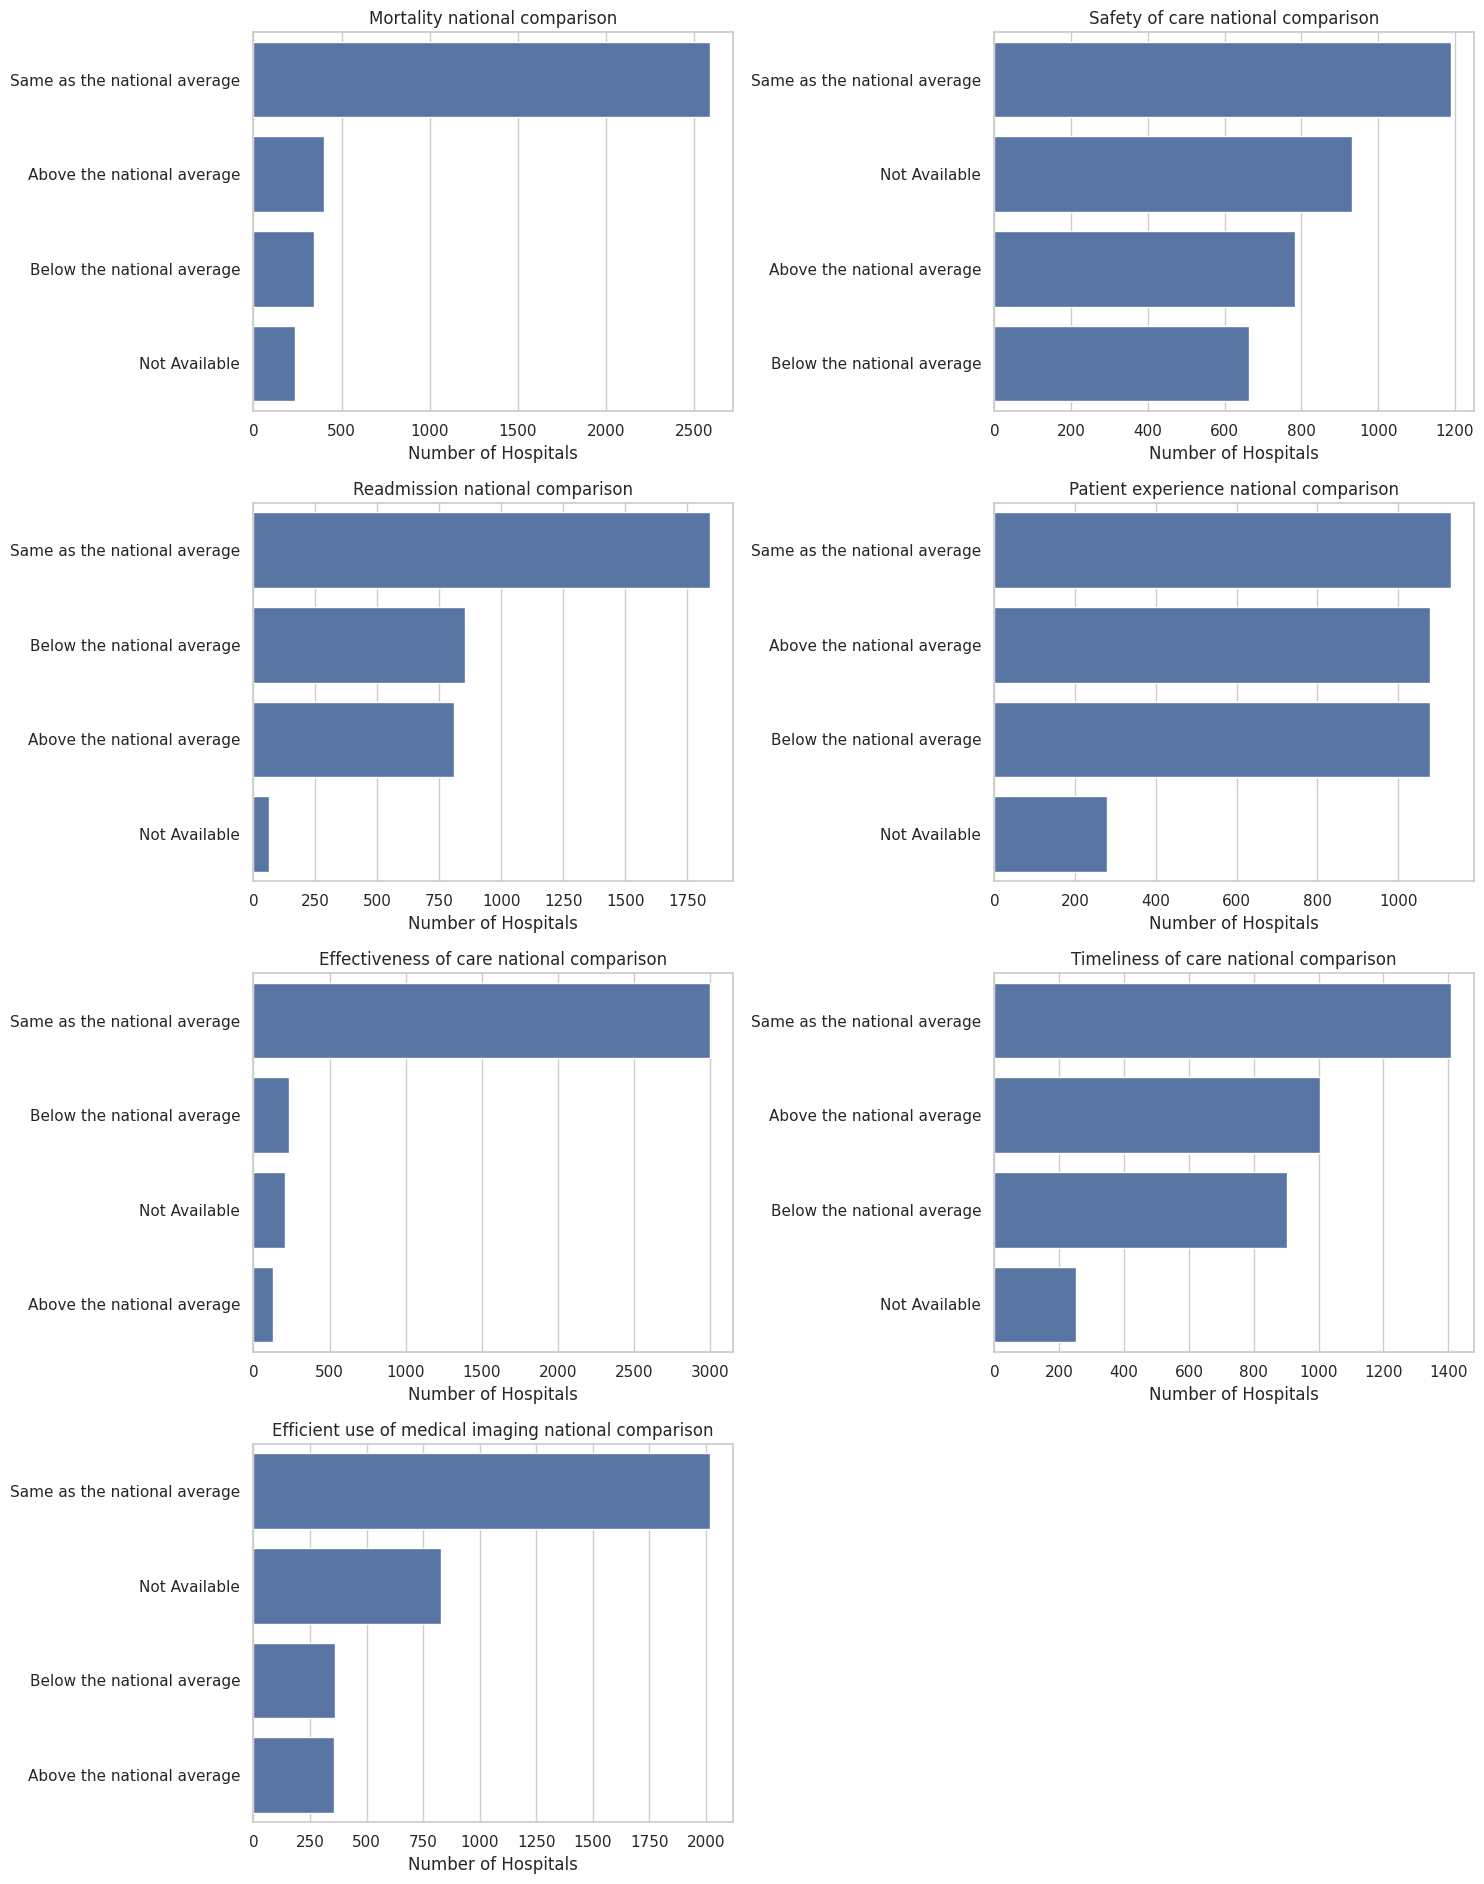

In [12]:

indicator_columns = [
    "Mortality national comparison",
    "Safety of care national comparison",
    "Readmission national comparison",
    "Patient experience national comparison",
    "Effectiveness of care national comparison",
    "Timeliness of care national comparison",
    "Efficient use of medical imaging national comparison"
]

fig, axes = plt.subplots(4, 2, figsize=(15, 19))
axes = axes.flatten()

for i, col in enumerate(indicator_columns):
    order = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=order, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("Number of Hospitals")
    axes[i].set_ylabel("")

axes[-1].axis("off")
plt.tight_layout()
plt.show()


In [13]:

comparison_columns = indicator_columns.copy()

score_mapping = {
    "above the national average": 1,
    "same as the national average": 0,
    "below the national average": -1
}

for col in comparison_columns:
    df[col + "_score"] = (
        df[col]
        .astype("string")
        .str.strip()
        .str.lower()
        .map(score_mapping)
    )

score_columns = [col + "_score" for col in comparison_columns]

df["Healthcare_Quality_Safety_Score"] = df[score_columns].mean(axis=1)
df["Available_Indicator_Count"] = df[score_columns].notna().sum(axis=1)

display(
    df[
        comparison_columns
        + ["Healthcare_Quality_Safety_Score", "Available_Indicator_Count"]
    ].head()
)


,Mortality national comparison,Safety of care national comparison,Readmission national comparison,Patient experience national comparison,Effectiveness of care national comparison,Timeliness of care national comparison,Efficient use of medical imaging national comparison,Healthcare_Quality_Safety_Score,Available_Indicator_Count
0,Below the national average,Same as the national average,Above the national average,Same as the national average,Same as the national average,Above the national average,Below the national average,0.000000,7
1,Below the national average,Same as the national average,Same as the national average,Same as the national average,Same as the national average,Above the national average,Same as the national average,0.000000,7
2,Same as the national average,Not Available,Same as the national average,Not Available,Same as the national average,Same as the national average,Not Available,0.000000,4
4,Below the national average,Above the national average,Same as the national average,Same as the national average,Same as the national average,Same as the national average,Same as the national average,0.000000,7
6,Same as the national average,Not Available,Same as the national average,Below the national average,Not Available,Not Available,Not Available,-0.333333,3


In [14]:

categorical_features = [
    "Hospital Type",
    "Hospital Ownership",
    "Emergency Services",
    "Meets criteria for meaningful use of EHRs"
] + comparison_columns

engineered_features = [
    "Healthcare_Quality_Safety_Score",
    "Available_Indicator_Count"
]

features = categorical_features + engineered_features

X = df[features].copy()
y = df[target].copy()

print("Number of input features:", len(features))
print("Target variable:", target)
print("Input shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())


Number of input features: 13
Target variable: Hospital overall rating
Input shape: (3567, 13)
Target shape: (3567,)


,Hospital Type,Hospital Ownership,Emergency Services,Meets criteria for meaningful use of EHRs,Mortality national comparison,Safety of care national comparison,Readmission national comparison,Patient experience national comparison,Effectiveness of care national comparison,Timeliness of care national comparison,Efficient use of medical imaging national comparison,Healthcare_Quality_Safety_Score,Available_Indicator_Count
0,Acute Care Hospitals,Government - Hospital District or Authority,True,True,Below the national average,Same as the national average,Above the national average,Same as the national average,Same as the national average,Above the national average,Below the national average,0.000000,7
1,Acute Care Hospitals,Proprietary,True,True,Below the national average,Same as the national average,Same as the national average,Same as the national average,Same as the national average,Above the national average,Same as the national average,0.000000,7
2,Acute Care Hospitals,Government - Hospital District or Authority,True,True,Same as the national average,Not Available,Same as the national average,Not Available,Same as the national average,Same as the national average,Not Available,0.000000,4
4,Acute Care Hospitals,Proprietary,True,True,Below the national average,Above the national average,Same as the national average,Same as the national average,Same as the national average,Same as the national average,Same as the national average,0.000000,7
6,Acute Care Hospitals,Tribal,True,True,Same as the national average,Not Available,Same as the national average,Below the national average,Not Available,Not Available,Not Available,-0.333333,3


In [15]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining rating distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting rating distribution:")
print(y_test.value_counts().sort_index())


Training records: 2853
Testing records: 714

Training rating distribution:
Hospital overall rating
1      86
2     542
3    1408
4     751
5      66
Name: count, dtype: int64

Testing rating distribution:
Hospital overall rating
1     21
2    136
3    353
4    188
5     16
Name: count, dtype: int64


In [16]:

categorical_features = X.select_dtypes(
    include=["object", "string", "bool", "category"]
).columns.tolist()

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['Healthcare_Quality_Safety_Score', 'Available_Indicator_Count']
Categorical features: ['Hospital Type', 'Hospital Ownership', 'Emergency Services', 'Meets criteria for meaningful use of EHRs', 'Mortality national comparison', 'Safety of care national comparison', 'Readmission national comparison', 'Patient experience national comparison', 'Effectiveness of care national comparison', 'Timeliness of care national comparison', 'Efficient use of medical imaging national comparison']


In [17]:

model_lr = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

model_lr.fit(X_train, y_train)

pred_lr = model_lr.predict(X_test)

print("Logistic Regression completed.")


Logistic Regression completed.


In [18]:

model_dt = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ))
])

model_dt.fit(X_train, y_train)

pred_dt = model_dt.predict(X_test)

print("Decision Tree completed.")


Decision Tree completed.


In [19]:

model_rf = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

model_rf.fit(X_train, y_train)

pred_rf = model_rf.predict(X_test)

print("Random Forest completed.")


Random Forest completed.


In [20]:

models_predictions = {
    "Logistic Regression": pred_lr,
    "Decision Tree": pred_dt,
    "Random Forest": pred_rf
}

results = []

for name, predictions in models_predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, average="weighted", zero_division=0
        )
    })

results_df = pd.DataFrame(results).sort_values(
    "F1 Score", ascending=False
)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.6639,0.7141,0.6639,0.6777
2,Random Forest,0.6611,0.6986,0.6611,0.6732
1,Decision Tree,0.5882,0.6604,0.5882,0.6089


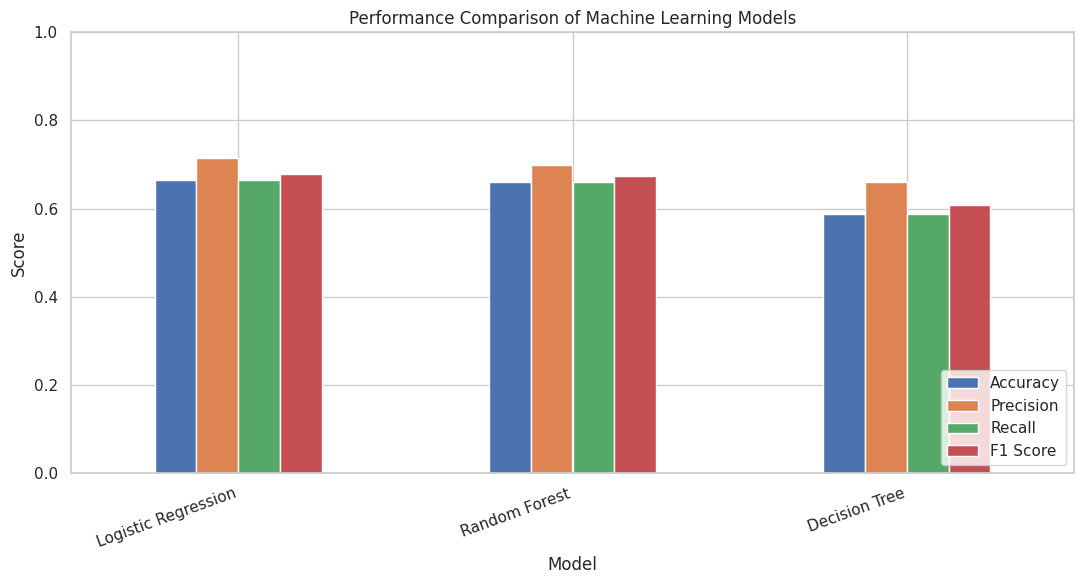

In [21]:

results_plot = results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
]

results_plot.plot(kind="bar", figsize=(11, 6))

plt.title("Performance Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


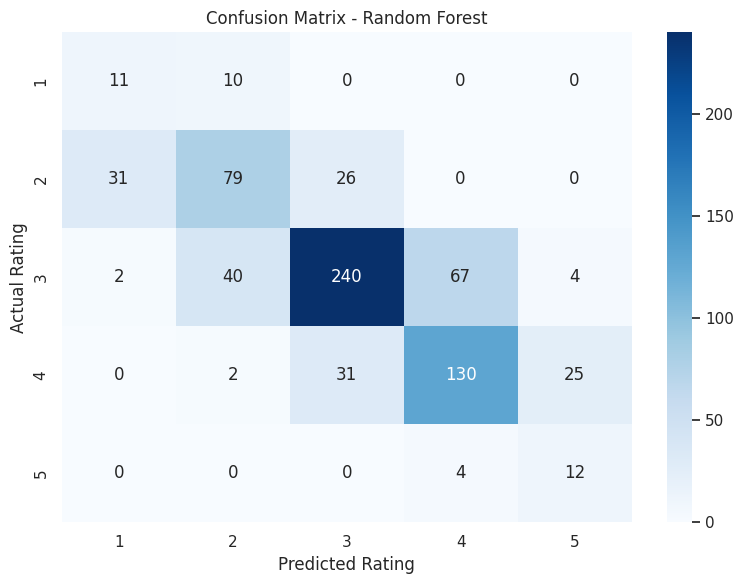

              precision    recall  f1-score   support

           1       0.25      0.52      0.34        21
           2       0.60      0.58      0.59       136
           3       0.81      0.68      0.74       353
           4       0.65      0.69      0.67       188
           5       0.29      0.75      0.42        16

    accuracy                           0.66       714
   macro avg       0.52      0.65      0.55       714
weighted avg       0.70      0.66      0.67       714



In [22]:

cm = confusion_matrix(y_test, pred_rf, labels=[1, 2, 3, 4, 5])

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[1, 2, 3, 4, 5],
    yticklabels=[1, 2, 3, 4, 5]
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Rating")
plt.ylabel("Actual Rating")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    pred_rf,
    labels=[1, 2, 3, 4, 5],
    zero_division=0
))


,Feature,Importance
0,num__Healthcare_Quality_Safety_Score,0.237961
30,cat__Patient experience national comparison_Be...,0.081463
29,cat__Patient experience national comparison_Ab...,0.076477
26,cat__Readmission national comparison_Below the...,0.061934
25,cat__Readmission national comparison_Above the...,0.053850
28,cat__Readmission national comparison_Same as t...,0.052526
22,cat__Safety of care national comparison_Below ...,0.052331
38,cat__Timeliness of care national comparison_Be...,0.036269
21,cat__Safety of care national comparison_Above ...,0.033078
17,cat__Mortality national comparison_Above the n...,0.023397


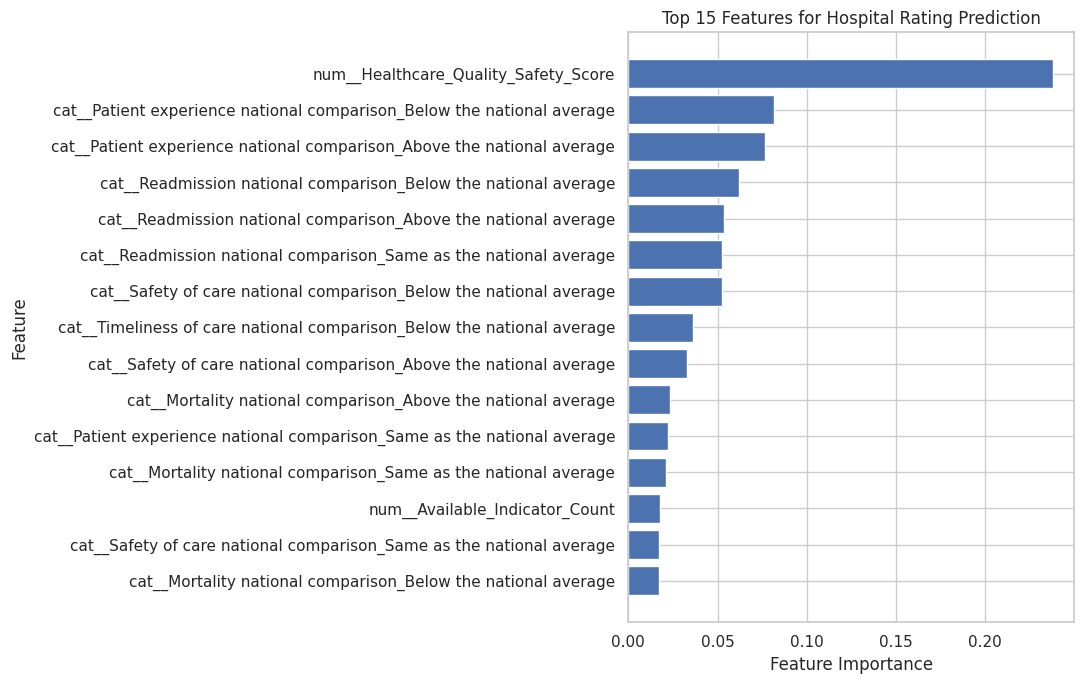

In [23]:

fitted_preprocessor = model_rf.named_steps["preprocessor"]
fitted_classifier = model_rf.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
importances = fitted_classifier.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

plt.figure(figsize=(11, 7))

top_features = importance_df.head(15).sort_values("Importance")

plt.barh(top_features["Feature"], top_features["Importance"])

plt.title("Top 15 Features for Hospital Rating Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [24]:

original_features = categorical_features.copy()

X_original = df[original_features].copy()
X_engineered = df[features].copy()

Xo_train, Xo_test, yo_train, yo_test = train_test_split(
    X_original, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

Xe_train, Xe_test, ye_train, ye_test = train_test_split(
    X_engineered, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

def make_rf_pipeline(X_data):
    cat_cols = X_data.select_dtypes(
        include=["object", "string", "bool", "category"]
    ).columns.tolist()

    num_cols = X_data.select_dtypes(
        include=["number"]
    ).columns.tolist()

    prep = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_cols)
    ])

    return Pipeline([
        ("preprocessor", prep),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            max_depth=12,
            min_samples_leaf=3,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])

rf_original = make_rf_pipeline(X_original)
rf_original.fit(Xo_train, yo_train)
pred_original = rf_original.predict(Xo_test)

rf_engineered = make_rf_pipeline(X_engineered)
rf_engineered.fit(Xe_train, ye_train)
pred_engineered = rf_engineered.predict(Xe_test)

novelty_results = pd.DataFrame([
    {
        "Approach": "Random Forest without engineered score",
        "Accuracy": accuracy_score(yo_test, pred_original),
        "F1 Score": f1_score(
            yo_test, pred_original, average="weighted", zero_division=0
        )
    },
    {
        "Approach": "Random Forest with engineered score",
        "Accuracy": accuracy_score(ye_test, pred_engineered),
        "F1 Score": f1_score(
            ye_test, pred_engineered, average="weighted", zero_division=0
        )
    }
])

display(novelty_results.round(4))


,Approach,Accuracy,F1 Score
0,Random Forest without engineered score,0.6429,0.6555
1,Random Forest with engineered score,0.6611,0.6732


In [25]:

results_df.to_csv("model_comparison.csv", index=False)
importance_df.to_csv("feature_importance.csv", index=False)
novelty_results.to_csv("feature_engineering_comparison.csv", index=False)

print("Result files saved.")


Result files saved.


In [26]:

from google.colab import files

files.download("model_comparison.csv")
files.download("feature_importance.csv")
files.download("feature_engineering_comparison.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:

import joblib

joblib.dump(model_rf, "hospital_rating_random_forest.pkl")

files.download("hospital_rating_random_forest.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>